# Práctica S1 POO II

Diagnóstico y refactorización. Identificador S1-001. Cambiar este identificador por ApellidoNombre al entregar.

El código y las explicaciones fueron elaborados con asistencia de IA. Las actividades Python pueden ejecutarse en orden sin archivos externos. Los bloques C++ se compilan en Colab.


## Actividad 1 Código y diagnóstico

Leer primero el ejemplo. Identificar nombres ambiguos, estado público, validación ausente, registros posicionales y presentación acoplada. La tabla completa está en ACTIVIDADES_RESUELTAS.md.


In [1]:
# Actividad 1: identificar los problemas de diseño del ejemplo original.
class est:
    def __init__(self, n, a, p):
        self.n = n
        self.a = a
        self.p = p
        self.h = []

    def add(self, c, n):
        self.h.append([c, n])

    def ppa(self):
        if len(self.h) == 0:
            return 0
        t = 0
        for i in self.h:
            t = t + i[1]
        return t / len(self.h)

    def pr(self):
        print(self.n, self.a, self.p, self.ppa())
        for i in self.h:
            print(i)


e1 = est("Juan Mamani", 20210500, "Ing. Sistemas")
e1.add("POO II", 16)
e1.add("BD I", 14)
e1.pr()


Juan Mamani 20210500 Ing. Sistemas 15.0
['POO II', 16]
['BD I', 14]


## Actividad 1 Diagnóstico antes de modificar

Las líneas corresponden a `baseline/estudiante_original.py`, copia del ejemplo ya indentado. Se analizó primero la fuente y después se ejecutó el caso inicial. Las notas 16 y 14 producen promedio 15.0. El caso sin notas ya estaba contemplado en el original; no se lo presenta como un defecto.

| Hallazgo | Líneas | Riesgo y corrección |
|---|---|---|
| Clase `est` poco expresiva | 2 | No comunica el concepto del dominio. Renombrar `Estudiante` y usar PascalCase. |
| Atributos, parámetros y métodos abreviados | 3 a 23 | `a`, `p`, `h`, `add`, `ppa` y `pr` exigen deducir su intención. Usar nombres como `codigo`, `escuela`, `notas` y `agregar_nota`. |
| Estado público sin acceso controlado | 4 a 7 | Un cliente puede reemplazar la colección o el código. Ofrecer propiedades de lectura y operaciones que preserven reglas. |
| Notas sin validar | 9 y 10 | Se admite 25 o un valor negativo. Rechazar valores fuera de 0 a 20 antes de agregarlos. |
| Registros posicionales | 10 y 17 | `i[1]` depende del orden de una lista. Reemplazarla por `Nota.curso` y `Nota.calificacion`. |
| Presentación acoplada a la entidad | 20 a 23 | Cambiar el formato de salida requiere editar `Estudiante`. Mover impresión al cliente y generación de reportes a otra clase. |
| Constructor sin contrato mínimo | 3 a 7 | Se aceptan nombre vacío o código sin identificar. Declarar y comprobar reglas mínimas de construcción. |
| Contratos y significado sin documentar | 2 a 23 | No explica el rango de notas ni si el promedio es ponderado. Documentar las reglas y comprobarlas con pruebas. |

Los dos primeros hallazgos separan el nombre del tipo de la nomenclatura de sus miembros. El diagnóstico también debe explicar los problemas de estado, validación, representación y responsabilidad; contar abreviaturas aisladas no sustituye ese análisis.



## Actividad 2 Entidades en Python

Cada operación valida antes de modificar el estado. El promedio es aritmético.


In [2]:
"""Entidades: conservan datos válidos y calculan resultados, sin archivos ni consola."""
from dataclasses import dataclass
from math import isfinite


@dataclass(frozen=True)
class Nota:
    curso: str
    calificacion: float

    def __post_init__(self):
        if not isinstance(self.curso, str) or not self.curso.strip():
            raise ValueError("El curso no puede estar vacio")
        if (isinstance(self.calificacion, bool)
                or not isinstance(self.calificacion, (int, float))
                or not isfinite(self.calificacion)
                or not 0 <= self.calificacion <= 20):
            raise ValueError("La nota debe estar entre 0 y 20")


class Estudiante:
    def __init__(self, nombre: str, codigo: str | int, escuela: str = "Ing. Sistemas"):
        if not isinstance(nombre, str) or not nombre.strip():
            raise ValueError("El nombre no puede estar vacio")
        if isinstance(codigo, bool) or not isinstance(codigo, (str, int)):
            raise ValueError("El codigo debe ser texto o un entero positivo")
        if (isinstance(codigo, int) and codigo <= 0) or not str(codigo).strip():
            raise ValueError("El codigo no puede estar vacio ni ser no positivo")
        if not isinstance(escuela, str) or not escuela.strip():
            raise ValueError("La escuela no puede estar vacia")
        self._nombre = nombre
        self._codigo = str(codigo)
        self._escuela = escuela
        self._notas: list[Nota] = []

    @property
    def nombre(self) -> str:
        return self._nombre

    @property
    def codigo(self) -> str:
        return self._codigo

    @property
    def escuela(self) -> str:
        return self._escuela

    @property
    def notas(self) -> tuple[Nota, ...]:
        # Una tupla de notas inmutables evita modificar la colección por esta interfaz.
        return tuple(self._notas)

    def agregar_nota(self, curso: str, calificacion: float) -> None:
        nota = Nota(curso, calificacion)  # Validar antes de modificar el estado.
        self._notas.append(nota)

    def calcular_ppa(self) -> float:
        if not self._notas:
            return 0.0
        return sum(nota.calificacion for nota in self._notas) / len(self._notas)

    def esta_aprobado(self) -> bool:
        return self.calcular_ppa() >= 10.5

    def __str__(self) -> str:
        # Representar no produce efectos de salida; la consola pertenece al programa principal.
        return f"[{self.codigo}] {self.nombre} ({self.escuela})"


In [3]:
e = Estudiante("Juan Carlos Mamani Quispe", 20210500)
e.agregar_nota("POO II", 16)
e.agregar_nota("BD I", 14)
assert e.calcular_ppa() == 15
print(e)
print(f"PPA: {e.calcular_ppa():.2f}")
try:
    e.agregar_nota("Redes", 25)
except ValueError as error:
    print("Error capturado:", error)


[20210500] Juan Carlos Mamani Quispe (Ing. Sistemas)
PPA: 15.00
Error capturado: La nota debe estar entre 0 y 20


## Parte II Componentes separados

Los siguientes módulos se incluyen aquí para hacer el notebook autocontenido. Se omiten sus importaciones relativas porque las clases ya están en celdas anteriores.


### Repositorio


In [4]:
"""Almacenamiento en memoria: no conoce CSV, JSON ni archivos."""


class RepositorioEstudiantes:
    def __init__(self):
        self._estudiantes: dict[str, Estudiante] = {}

    def guardar(self, estudiante: Estudiante) -> None:
        if estudiante.codigo in self._estudiantes:
            raise ValueError("El codigo ya esta registrado")
        self._estudiantes[estudiante.codigo] = estudiante

    def buscar(self, codigo: str | int) -> Estudiante:
        try:
            return self._estudiantes[str(codigo)]
        except KeyError:
            raise ValueError("Estudiante no encontrado") from None

    def todos(self) -> tuple[Estudiante, ...]:
        return tuple(self._estudiantes.values())

### Auditoria


In [5]:
"""El destino de auditoría se elige al construir el servicio."""
from pathlib import Path


class AuditoriaMemoria:
    def __init__(self):
        self._eventos: list[str] = []

    def registrar(self, evento: str) -> None:
        self._eventos.append(evento)

    @property
    def eventos(self) -> tuple[str, ...]:
        return tuple(self._eventos)


class AuditoriaArchivo:
    def __init__(self, ruta: str | Path):
        self._ruta = Path(ruta)

    def registrar(self, evento: str) -> None:
        with self._ruta.open("a", encoding="utf-8") as archivo:
            archivo.write(evento + "\n")

### Reportes


In [6]:
"""Generación pura: devuelve texto y deja al cliente decidir dónde guardarlo."""
import csv
import io
from collections.abc import Iterable



class GeneradorCSV:
    def generar(self, estudiantes: Iterable[Estudiante]) -> str:
        salida = io.StringIO(newline="")
        escritor = csv.writer(salida, delimiter=";", lineterminator="\n")
        for estudiante in estudiantes:
            escritor.writerow([
                estudiante.codigo,
                estudiante.nombre,
                f"{estudiante.calcular_ppa():.2f}",
                "APROBADO" if estudiante.esta_aprobado() else "DESAPROBADO",
            ])
        return salida.getvalue().removesuffix("\n")

### Servicio


In [7]:
"""Coordinación: las dependencias se reciben, no se crean internamente."""


class ServicioAcademico:
    def __init__(self, repositorio: RepositorioEstudiantes, auditoria):
        self._repositorio = repositorio
        self._auditoria = auditoria

    def registrar(self, codigo: str | int, nombre: str, escuela="Ing. Sistemas") -> Estudiante:
        estudiante = Estudiante(nombre, codigo, escuela)
        self._repositorio.guardar(estudiante)
        return estudiante

    def agregar_nota(self, codigo: str | int, nota: float, curso="General") -> None:
        estudiante = self._repositorio.buscar(codigo)
        estudiante.agregar_nota(curso, nota)
        self._auditoria.registrar(f"nota:{codigo}:{nota:g}")

    def reporte(self, generador) -> str:
        return generador.generar(self._repositorio.todos())

### Reportes json


In [8]:
"""Segundo formato incorporado sin editar dominio, servicio ni CSV."""
import json
from collections.abc import Iterable



class GeneradorJSON:
    def generar(self, estudiantes: Iterable[Estudiante]) -> str:
        filas = [{
            "codigo": estudiante.codigo,
            "nombre": estudiante.nombre,
            "promedio": estudiante.calcular_ppa(),
            "estado": "APROBADO" if estudiante.esta_aprobado() else "DESAPROBADO",
        } for estudiante in estudiantes]
        return json.dumps(filas, ensure_ascii=False, allow_nan=False)

In [9]:
repo = RepositorioEstudiantes()
auditoria = AuditoriaMemoria()
servicio = ServicioAcademico(repo, auditoria)
servicio.registrar("E001", "Ana")
servicio.agregar_nota("E001", 10)
servicio.agregar_nota("E001", 11)
assert repo.buscar("E001").calcular_ppa() == 10.5
assert repo.buscar("E001").esta_aprobado()
print(servicio.reporte(GeneradorCSV()))
print(servicio.reporte(GeneradorJSON()))


E001;Ana;10.50;APROBADO
[{"codigo": "E001", "nombre": "Ana", "promedio": 10.5, "estado": "APROBADO"}]


## Actividad 3 Solución y pruebas Cpp

Los encabezados se reúnen en un solo archivo por demostración para poder ejecutar este notebook en Colab. Las fuentes organizadas permanecen en la carpeta cpp de la entrega.


In [ ]:
%%writefile estudiante.cpp
#include <cmath>
#include <stdexcept>
#include <string>
#include <utility>
#include <vector>

struct Nota {
    std::string curso;
    double calificacion;
};

inline bool vacio(const std::string& valor) {
    return valor.find_first_not_of(" \t\r\n") == std::string::npos;
}

class Estudiante {
    std::string nombre_;
    std::string codigo_;
    std::string escuela_;
    std::vector<Nota> notas_;

public:
    Estudiante(std::string nombre, std::string codigo,
               std::string escuela = "Ing. Sistemas")
        : nombre_(std::move(nombre)), codigo_(std::move(codigo)),
          escuela_(std::move(escuela)) {
        if (vacio(nombre_)) throw std::invalid_argument("El nombre no puede estar vacio");
        if (vacio(codigo_)) throw std::invalid_argument("El codigo no puede estar vacio");
        if (vacio(escuela_)) throw std::invalid_argument("La escuela no puede estar vacia");
    }

    Estudiante(std::string nombre, int codigo, std::string escuela = "Ing. Sistemas")
        : Estudiante(std::move(nombre), std::to_string(codigo), std::move(escuela)) {
        if (codigo <= 0) throw std::invalid_argument("El codigo debe ser positivo");
    }

    const std::string& getNombre() const { return nombre_; }
    const std::string& getCodigo() const { return codigo_; }
    const std::string& getEscuela() const { return escuela_; }
    const std::vector<Nota>& getNotas() const { return notas_; }

    void agregarNota(const std::string& curso, double calificacion) {
        if (vacio(curso)) throw std::invalid_argument("El curso no puede estar vacio");
        if (!std::isfinite(calificacion) || calificacion < 0 || calificacion > 20)
            throw std::invalid_argument("La nota debe estar entre 0 y 20");
        notas_.push_back({curso, calificacion});
    }

    double calcularPPA() const {
        if (notas_.empty()) return 0.0;
        double suma = 0.0;
        for (const auto& nota : notas_) suma += nota.calificacion;
        return suma / static_cast<double>(notas_.size());
    }

    bool estaAprobado() const { return calcularPPA() >= 10.5; }

    std::string descripcion() const {
        return "[" + codigo_ + "] " + nombre_ + " (" + escuela_ + ")";
    }
};
#include <iomanip>
#include <iostream>

int main() {
    Estudiante estudiante("Juan Carlos Mamani Quispe", 20210500, "Ing. Sistemas");
    estudiante.agregarNota("POO II", 16);
    estudiante.agregarNota("Base de Datos I", 14);
    std::cout << estudiante.descripcion() << '\n';
    std::cout << "PPA: " << std::fixed << std::setprecision(2)
              << estudiante.calcularPPA() << '\n';
    try {
        estudiante.agregarNota("Redes", 25);
    } catch (const std::invalid_argument& error) {
        std::cout << "Error capturado: " << error.what() << '\n';
    }
}


In [ ]:
!g++ -std=c++17 -Wall -Wextra -Wpedantic -Werror estudiante.cpp -o estudiante
!./estudiante


In [ ]:
%%writefile pruebas.cpp
#include <cmath>
#include <stdexcept>
#include <string>
#include <utility>
#include <vector>

struct Nota {
    std::string curso;
    double calificacion;
};

inline bool vacio(const std::string& valor) {
    return valor.find_first_not_of(" \t\r\n") == std::string::npos;
}

class Estudiante {
    std::string nombre_;
    std::string codigo_;
    std::string escuela_;
    std::vector<Nota> notas_;

public:
    Estudiante(std::string nombre, std::string codigo,
               std::string escuela = "Ing. Sistemas")
        : nombre_(std::move(nombre)), codigo_(std::move(codigo)),
          escuela_(std::move(escuela)) {
        if (vacio(nombre_)) throw std::invalid_argument("El nombre no puede estar vacio");
        if (vacio(codigo_)) throw std::invalid_argument("El codigo no puede estar vacio");
        if (vacio(escuela_)) throw std::invalid_argument("La escuela no puede estar vacia");
    }

    Estudiante(std::string nombre, int codigo, std::string escuela = "Ing. Sistemas")
        : Estudiante(std::move(nombre), std::to_string(codigo), std::move(escuela)) {
        if (codigo <= 0) throw std::invalid_argument("El codigo debe ser positivo");
    }

    const std::string& getNombre() const { return nombre_; }
    const std::string& getCodigo() const { return codigo_; }
    const std::string& getEscuela() const { return escuela_; }
    const std::vector<Nota>& getNotas() const { return notas_; }

    void agregarNota(const std::string& curso, double calificacion) {
        if (vacio(curso)) throw std::invalid_argument("El curso no puede estar vacio");
        if (!std::isfinite(calificacion) || calificacion < 0 || calificacion > 20)
            throw std::invalid_argument("La nota debe estar entre 0 y 20");
        notas_.push_back({curso, calificacion});
    }

    double calcularPPA() const {
        if (notas_.empty()) return 0.0;
        double suma = 0.0;
        for (const auto& nota : notas_) suma += nota.calificacion;
        return suma / static_cast<double>(notas_.size());
    }

    bool estaAprobado() const { return calcularPPA() >= 10.5; }

    std::string descripcion() const {
        return "[" + codigo_ + "] " + nombre_ + " (" + escuela_ + ")";
    }
};
#include <fstream>
#include <iomanip>
#include <sstream>

class RepositorioEstudiantes {
    std::vector<Estudiante> estudiantes_;

public:
    void guardar(Estudiante estudiante) {
        for (const auto& actual : estudiantes_)
            if (actual.getCodigo() == estudiante.getCodigo())
                throw std::invalid_argument("El codigo ya esta registrado");
        estudiantes_.push_back(std::move(estudiante));
    }

    Estudiante& buscar(const std::string& codigo) {
        for (auto& estudiante : estudiantes_)
            if (estudiante.getCodigo() == codigo) return estudiante;
        throw std::invalid_argument("Estudiante no encontrado");
    }

    const std::vector<Estudiante>& todos() const { return estudiantes_; }
};

class Auditoria {
public:
    virtual ~Auditoria() = default;
    virtual void registrar(const std::string& evento) = 0;
};

class AuditoriaMemoria : public Auditoria {
    std::vector<std::string> eventos_;

public:
    void registrar(const std::string& evento) override { eventos_.push_back(evento); }
    const std::vector<std::string>& eventos() const { return eventos_; }
};

class AuditoriaArchivo : public Auditoria {
    std::string ruta_;

public:
    explicit AuditoriaArchivo(std::string ruta) : ruta_(std::move(ruta)) {}
    void registrar(const std::string& evento) override {
        std::ofstream archivo(ruta_, std::ios::app);
        if (!archivo) throw std::runtime_error("No se pudo abrir la auditoria");
        archivo << evento << '\n';
        if (!archivo) throw std::runtime_error("No se pudo escribir la auditoria");
    }
};

class GeneradorReporte {
public:
    virtual ~GeneradorReporte() = default;
    virtual std::string generar(const std::vector<Estudiante>& estudiantes) const = 0;
};

inline std::string campoCSV(const std::string& valor) {
    if (valor.find_first_of(";\"\n\r") == std::string::npos) return valor;
    std::string salida = "\"";
    for (char letra : valor) {
        if (letra == '"') salida += '"';
        salida += letra;
    }
    return salida + '"';
}

class GeneradorCSV : public GeneradorReporte {
public:
    std::string generar(const std::vector<Estudiante>& estudiantes) const override {
        std::ostringstream salida;
        bool primera = true;
        for (const auto& estudiante : estudiantes) {
            if (!primera) salida << '\n';
            primera = false;
            salida << campoCSV(estudiante.getCodigo()) << ';'
                   << campoCSV(estudiante.getNombre()) << ';'
                   << std::fixed << std::setprecision(2) << estudiante.calcularPPA() << ';'
                   << (estudiante.estaAprobado() ? "APROBADO" : "DESAPROBADO");
        }
        return salida.str();
    }
};

class ServicioAcademico {
    RepositorioEstudiantes& repositorio_;
    Auditoria& auditoria_;

public:
    ServicioAcademico(RepositorioEstudiantes& repositorio, Auditoria& auditoria)
        : repositorio_(repositorio), auditoria_(auditoria) {}

    void registrar(const std::string& codigo, const std::string& nombre) {
        repositorio_.guardar(Estudiante(nombre, codigo));
    }

    void agregarNota(const std::string& codigo, double nota,
                     const std::string& curso = "General") {
        repositorio_.buscar(codigo).agregarNota(curso, nota);
        std::ostringstream evento;
        evento << "nota:" << codigo << ':' << nota;
        auditoria_.registrar(evento.str());
    }

    std::string reporte(const GeneradorReporte& generador) const {
        return generador.generar(repositorio_.todos());
    }
};

inline std::string cadenaJSON(const std::string& valor) {
    std::ostringstream salida;
    salida << '"';
    for (unsigned char caracter : valor) {
        if (caracter == '"') salida << "\\\"";
        else if (caracter == '\\') salida << "\\\\";
        else if (caracter < 32)
            salida << "\\u" << std::hex << std::setw(4) << std::setfill('0')
                   << static_cast<unsigned int>(caracter) << std::dec;
        else salida << static_cast<char>(caracter);
    }
    salida << '"';
    return salida.str();
}

class GeneradorJSON : public GeneradorReporte {
public:
    std::string generar(const std::vector<Estudiante>& estudiantes) const override {
        std::ostringstream salida;
        salida << '[';
        bool primera = true;
        for (const auto& estudiante : estudiantes) {
            if (!primera) salida << ',';
            primera = false;
            salida << "{\"codigo\":" << cadenaJSON(estudiante.getCodigo())
                   << ",\"nombre\":" << cadenaJSON(estudiante.getNombre())
                   << ",\"promedio\":" << std::setprecision(17) << estudiante.calcularPPA()
                   << ",\"estado\":"
                   << cadenaJSON(estudiante.estaAprobado() ? "APROBADO" : "DESAPROBADO") << '}';
        }
        salida << ']';
        return salida.str();
    }
};
#include <functional>
#include <iostream>
#include <limits>

void exigir(bool condicion) {
    if (!condicion) throw std::runtime_error("Resultado distinto al esperado");
}

template <typename Accion>
void rechaza(Accion accion) {
    bool rechazado = false;
    try { accion(); } catch (const std::invalid_argument&) { rechazado = true; }
    exigir(rechazado);
}

int main() {
    using Caso = std::pair<std::string, std::function<void()>>;
    std::vector<Caso> casos = {
        {"promedio sin notas", [] {
            Estudiante e("Ana", "E001"); exigir(e.calcularPPA() == 0);
        }},
        {"promedio 16 y 14", [] {
            Estudiante e("Ana", "E001"); e.agregarNota("A", 16); e.agregarNota("B", 14);
            exigir(e.calcularPPA() == 15);
        }},
        {"tres notas", [] {
            Estudiante e("Ana", "E001");
            for (double n : {12, 14, 16}) e.agregarNota("Curso", n);
            exigir(e.calcularPPA() == 14);
        }},
        {"extremos 0 y 20", [] {
            Estudiante e("Ana", "E001"); e.agregarNota("A", 0); e.agregarNota("B", 20);
            exigir(e.calcularPPA() == 10);
        }},
        {"limite 10.5", [] {
            Estudiante e("Ana", "E001"); e.agregarNota("A", 10);
            exigir(!e.estaAprobado()); e.agregarNota("B", 11); exigir(e.estaAprobado());
        }},
        {"nota negativa", [] {
            Estudiante e("Ana", "E001"); rechaza([&] { e.agregarNota("A", -0.1); });
            exigir(e.getNotas().empty());
        }},
        {"nota superior", [] {
            Estudiante e("Ana", "E001"); rechaza([&] { e.agregarNota("A", 20.1); });
            exigir(e.getNotas().empty());
        }},
        {"nota no finita", [] {
            Estudiante e("Ana", "E001");
            rechaza([&] { e.agregarNota("A", std::numeric_limits<double>::quiet_NaN()); });
            rechaza([&] { e.agregarNota("A", std::numeric_limits<double>::infinity()); });
        }},
        {"nombre vacio", [] { rechaza([] { Estudiante e(" ", "E001"); }); }},
        {"codigo vacio", [] { rechaza([] { Estudiante e("Ana", ""); }); }},
        {"codigo entero invalido", [] { rechaza([] { Estudiante e("Ana", 0); }); }},
        {"escuela vacia", [] { rechaza([] { Estudiante e("Ana", "E001", ""); }); }},
        {"curso vacio", [] {
            Estudiante e("Ana", "E001"); rechaza([&] { e.agregarNota(" ", 16); });
        }},
        {"registrar y recuperar", [] {
            RepositorioEstudiantes repo; repo.guardar(Estudiante("Ana", "E001"));
            exigir(repo.buscar("E001").getNombre() == "Ana");
        }},
        {"codigo duplicado", [] {
            RepositorioEstudiantes repo; repo.guardar(Estudiante("Ana", "E001"));
            rechaza([&] { repo.guardar(Estudiante("Otra", "E001")); });
            exigir(repo.todos().size() == 1);
        }},
        {"codigo inexistente", [] {
            RepositorioEstudiantes repo; rechaza([&] { repo.buscar("NO"); });
        }},
        {"auditoria valida", [] {
            RepositorioEstudiantes repo; AuditoriaMemoria auditoria;
            ServicioAcademico servicio(repo, auditoria); servicio.registrar("E001", "Ana");
            servicio.agregarNota("E001", 16); exigir(auditoria.eventos().at(0) == "nota:E001:16");
        }},
        {"invalida sin auditoria", [] {
            RepositorioEstudiantes repo; AuditoriaMemoria auditoria;
            ServicioAcademico servicio(repo, auditoria); servicio.registrar("E001", "Ana");
            rechaza([&] { servicio.agregarNota("E001", 25); });
            exigir(auditoria.eventos().empty());
        }},
        {"reporte sin cambiar notas", [] {
            RepositorioEstudiantes repo; AuditoriaMemoria auditoria;
            ServicioAcademico servicio(repo, auditoria); servicio.registrar("E001", "Ana");
            servicio.agregarNota("E001", 10); servicio.agregarNota("E001", 11);
            exigir(servicio.reporte(GeneradorCSV()) == "E001;Ana;10.50;APROBADO");
            exigir(repo.buscar("E001").getNotas().size() == 2);
        }},
        {"CSV escapa separadores", [] {
            exigir(campoCSV("Ana; \"Luz\"") == "\"Ana; \"\"Luz\"\"\"");
        }},
        {"JSON vacio", [] {
            exigir(GeneradorJSON().generar({}) == "[]");
        }},
        {"JSON escapa caracteres", [] {
            exigir(cadenaJSON("Ana\n\"Luz\"") == "\"Ana\\u000a\\\"Luz\\\"\"");
        }},
        {"JSON no cambia estado", [] {
            RepositorioEstudiantes repo; AuditoriaMemoria auditoria;
            ServicioAcademico servicio(repo, auditoria); servicio.registrar("E001", "Ana");
            servicio.agregarNota("E001", 10); servicio.agregarNota("E001", 11);
            const auto csv = servicio.reporte(GeneradorCSV());
            const auto json = servicio.reporte(GeneradorJSON());
            exigir(json.find("\"promedio\":10.5") != std::string::npos);
            exigir(servicio.reporte(GeneradorCSV()) == csv);
            exigir(repo.buscar("E001").getNotas().size() == 2);
        }},
        {"auditoria a archivo", [] {
            const std::string ruta = ".build/auditoria_prueba.txt";
            { std::ofstream limpiar(ruta, std::ios::trunc); }
            AuditoriaArchivo auditoria(ruta); auditoria.registrar("evento");
            std::ifstream archivo(ruta); std::string linea; std::getline(archivo, linea);
            exigir(linea == "evento");
        }},
    };
    std::size_t aprobados = 0;
    for (const auto& caso : casos) {
        try { caso.second(); ++aprobados; std::cout << "OK " << caso.first << '\n'; }
        catch (const std::exception& error) {
            std::cerr << "FALLO " << caso.first << ": " << error.what() << '\n';
        }
    }
    std::cout << aprobados << '/' << casos.size() << " pruebas aprobadas\n";
    return aprobados == casos.size() ? 0 : 1;
}


In [ ]:
!mkdir -p .build
!g++ -std=c++20 -Wall -Wextra -Wpedantic -Werror pruebas.cpp -o pruebas
!./pruebas


## Actividad 4 Cohesión y acoplamiento

**Cuál diseño tiene mayor cohesión y por qué.** El diseño B reúne las operaciones de notas y promedio en `Estudiante`, el almacenamiento en el repositorio y la exportación en su generador. Cada componente tiene una finalidad identificable. Una clase puede tener pocos métodos y seguir siendo poco cohesiva si esos métodos atienden tareas independientes.

**Qué sucede con el diseño A al cambiar el formato de exportación.** Hay que editar una clase que también registra estudiantes y calcula promedios. Eso obliga a revisar operaciones ajenas al reporte y amplía el riesgo de regresión. En B se cambia o agrega el generador, manteniendo estable la entidad.

**Qué principio SOLID se incumple.** El principio de responsabilidad única: la clase A cambia por reglas académicas, persistencia, presentación y notificaciones. Son motivos de cambio distintos, aunque todos aparezcan dentro del mismo sistema.

**Por qué B facilita las pruebas.** Es posible probar promedios sin crear archivos ni enviar correos. El servicio recibe un repositorio y una auditoría que pueden funcionar en memoria. Un generador se prueba comparando su texto con el resultado esperado. Tener más clases ayuda cuando sus límites expresan responsabilidades reales; no es por sí solo una medida de calidad.

## Actividad 5 Propuesta inicial del proyecto integrador

**Nombre:** Sistema de reservas de hotel en Puno. **Problema:** organizar los datos de huéspedes, habitaciones y reservas para reducir registros dispersos y permitir el control de disponibilidad en etapas posteriores. **Usuarios:** recepción, administración y personal encargado de reservas. El tema coincide con `plan_trabajo_proyecto_hotel_POO2.md` y con el README del proyecto que ya existe en la carpeta del curso.

| Clase candidata | Atributos privados iniciales | Responsabilidad |
|---|---|---|
| `Huesped` | `id`, `nombre`, `documento` | Identificar a la persona que solicita alojamiento. |
| `Habitacion` | `numero`, `tipo`, `capacidad` | Describir una unidad de alojamiento y su capacidad. |
| `Reserva` | `codigo`, `fechaEntrada`, `fechaSalida`, `estado` | Representar una solicitud de alojamiento con sus fechas y estado. |

El diagrama `proyecto_integrador/clases_iniciales.png` contiene estas tres clases con visibilidad privada y sin relaciones. Se acompaña de `clases_iniciales.drawio` editable. Las relaciones, herencia, tarifas y persistencia quedan fuera de este modelo inicial.

Se creó un repositorio Git local de la práctica con etapas baseline, tests, refactor y final. No hay una URL de GitHub verificada ni se publicó el proyecto; esa dirección debe completarse cuando el estudiante cree o vincule su repositorio. El nombre propuesto por la guía es `POO2-2026II-Apellido`, sustituyendo Apellido por el dato real.



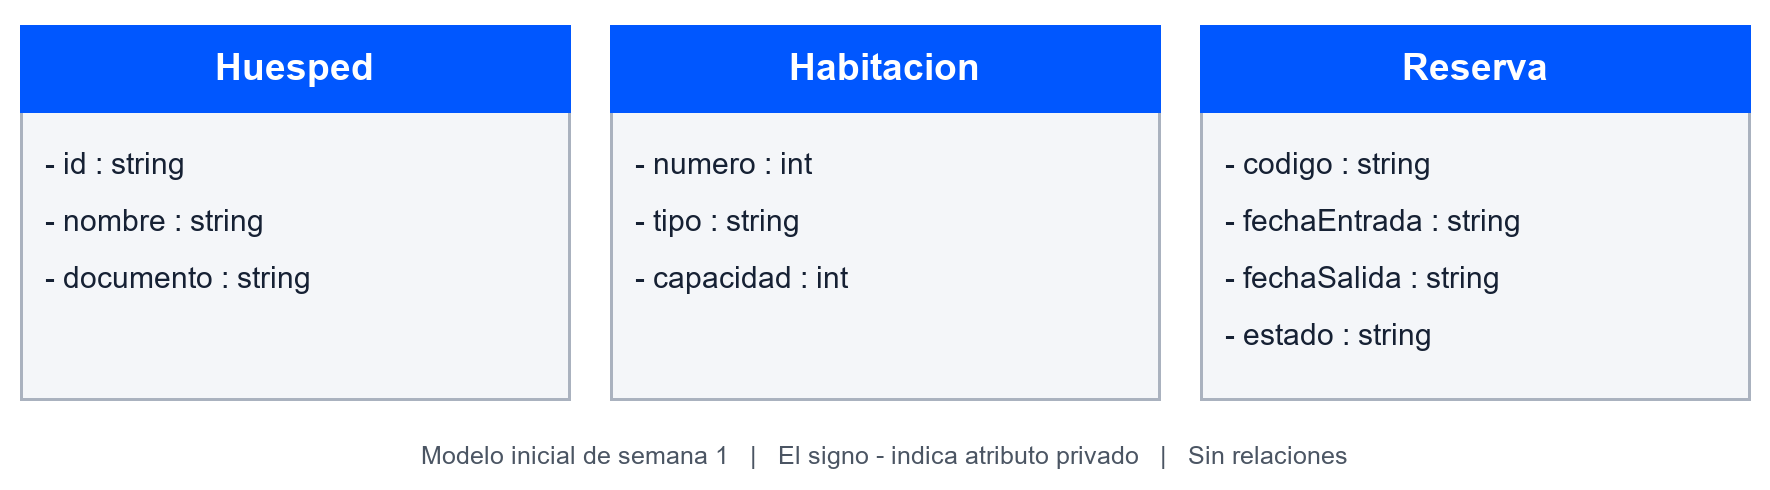

In [ ]:
# Diagrama UML inicial incorporado en la salida de esta celda.


## Preguntas de reflexión

**Defecto más perjudicial para el mantenimiento.** Mezclar reglas, archivos y presentación hace que cambios frecuentes en reportes obliguen a tocar la misma clase que administra notas. El estado público agrava el problema al permitir datos que incumplen esas reglas. Separar responsabilidades y proteger las operaciones ataca ambos riesgos.

**Atributos privados en ambos lenguajes.** `_nombre` es una convención de Python. `__nombre` activa modificación de nombre para evitar colisiones y acceso accidental, pero tampoco es una barrera absoluta. En C++, `nombre_` no significa privado por su sufijo; la restricción surge de `private` o del acceso privado por defecto de `class`. Las propiedades y getters permiten consultar sin ofrecer una asignación libre.

**Más clases y archivos en el diseño B.** Aumentan la navegación y el ensamblaje inicial, pero permiten modificar y probar responsabilidades por separado. El diseño A puede ser razonable en una demostración breve y descartable con requisitos estables; deja de ser cómodo cuando aparecen nuevos formatos o destinos.

**Git desde el comienzo.** Conserva la versión inicial, permite revisar qué cambió y relaciona cada mejora con sus pruebas. Un único commit final pierde la evidencia del proceso. El historial local de esta entrega conserva las etapas reales y utiliza una identidad de asistente, sin atribuirlas al estudiante.

## Preguntas de análisis e investigación

**Pocos métodos y baja cohesión.** Sí: una clase con solo `promedio` y `enviar_correo` reúne reglas académicas y comunicación externa. La cantidad de métodos no describe su unidad de propósito.

**Cuándo extraer clases aumenta innecesariamente el acoplamiento.** Cuando se crean envoltorios sin responsabilidad estable y cada operación exige atravesar muchos objetos que conocen sus detalles. Deben extraerse conceptos con un motivo de cambio propio y una interfaz pequeña.

**Refactorizar y reescribir.** Refactorizar cambia la organización manteniendo una conducta observada y comprobada. Reescribir construye otra solución, con mayor riesgo de omitir casos existentes. Incorporar validaciones nuevas se documentó separadamente del mantenimiento de los resultados válidos.

**Repositorio en base de datos.** El dominio puede conservarse si el repositorio mantiene su contrato. Harían falta pruebas de integración, un criterio para duplicados, manejo de conexiones y transacciones; la latencia y los fallos externos cambiarían las mediciones.

**Hipótesis para comparar estudiante, IA y estudiante con IA.** Bajo la misma tarea y pruebas de aceptación, la colaboración podría reducir el tiempo frente al estudiante solo manteniendo una comprensión que debe comprobarse mediante explicación individual. Es una hipótesis, no un resultado de esta entrega. Para contrastarla se requieren varios participantes, asignación de condiciones, tareas equivalentes, tiempo medido, tasa de pruebas y evaluación ciega de las explicaciones.

## Declaración de uso de IA

Se utilizó Codex para analizar la guía, generar las soluciones académicas Python y C++, escribir pruebas, ejecutar verificaciones, construir los diagramas y redactar este informe y sus anexos. La ejecución y los resultados conservados pertenecen a esta sesión asistida. No se atribuyen al estudiante horas de trabajo, comprensión individual, sustentación ni resultados experimentales humanos. El estudiante debe estudiar el material, verificarlo en su entorno y declarar el apoyo según las indicaciones del curso.

## Referencias y evidencia

- Zanabria Gálvez, A. H. (2026). Guía de práctica de laboratorio Semana 1, SIS206 POO II, UNAP. Material proporcionado, páginas 1 a 13.
- Plan de trabajo del sistema de reservas de hotel POO II y README del proyecto local, consultados para mantener el tema del proyecto integrador.
- Fuentes de esta entrega: `baseline/`, `python/`, `cpp/` y `tests/`.
- Resultados: `evidencias/verificacion.json`, salidas de pruebas y `metricas.csv`.

Las obras de Fowler y Martin aparecen en la bibliografía de la guía. No se afirma haber consultado esos libros para medir ni ejecutar esta entrega.
